
# Telco Customer Churn — Data Quality Audit

## Objective

This notebook performs an initial data quality assessment of the Telco Customer Churn dataset before exploratory analysis and machine learning.

The audit focuses on:
- Dataset structure and variable types
- Missing and invalid values
- Duplicate records and customer identifiers
- Categorical variables and business consistency
- Numerical ranges and outlier detection

The goal is to identify data quality issues, document preprocessing decisions, and preserve the original dataset.


In [13]:
# Standard library
import sys
from pathlib import Path

# Data manipulation
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Custom validation utilities
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_validation import (
    detect_non_numeric,
    summarize_categories,
    detect_outliers_iqr,
)

# Automatically reload modified Python modules
%load_ext autoreload
%autoreload 2

# Display configuration
pd.set_option("display.max_columns", None)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
data_path = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

if not data_path.exists():
    data_path = Path("data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(data_path)

display(df.head())

df.shape

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


(7043, 21)


## 1. Data Types Inspection

We examine the dataset structure, column types, and non-null counts to identify variables requiring further validation.

**Findings:**
- The dataset contains 7,043 observations and 21 columns.
- Most variables are categorical.
- `TotalCharges` is stored as a string instead of a numerical variable.
- `SeniorCitizen` is stored as an integer but represents a binary categorical feature.

These observations will guide the preprocessing strategy.


In [ ]:
df.info()
df.dtypes.value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

str        18
int64       2
float64     1
Name: count, dtype: int64


## 2. Missing Values Analysis

We investigate missing values and non-numeric entries that may not be detected by standard null checks.

Although the dataset contains no conventional missing values, `TotalCharges` is stored as a string and requires additional validation.

The `detect_non_numeric()` utility is used to identify entries that cannot be converted into numerical values.


In [5]:


df.isna().sum()


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:

string_cols = df.select_dtypes(
    include=["object", "string"]
).columns

empty_strings = df[string_cols].apply(
    lambda col: col.astype("string").str.strip().eq("").sum()
)

display(empty_strings[empty_strings > 0])


TotalCharges    11
dtype: int64

In [6]:

invalid_mask = detect_non_numeric(df["TotalCharges"])

print("Invalid values:", invalid_mask.sum())

display(
    df.loc[
        invalid_mask,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)


Invalid values: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,



### 2.1 Investigating Invalid TotalCharges

We examine the relationship between invalid `TotalCharges` values and customer tenure to determine whether these entries follow a consistent pattern.

**Findings:**
- 11 invalid entries were identified.
- All affected customers have `tenure = 0`.
- No customers with positive tenure have invalid `TotalCharges`.
- All 11 affected customers belong to the non-churn class.

**Preprocessing decision:** Replace these values with zero, under the assumption that customers with zero tenure have not yet accumulated charges.

The correction will be implemented during preprocessing, leaving the original dataset unchanged.


In [ ]:
# Customers with zero tenure
zero_tenure = df["tenure"] == 0

print("Customers with tenure = 0:", zero_tenure.sum())

print(
    "Invalid TotalCharges with tenure > 0:",
    (invalid_mask & ~zero_tenure).sum()
)

print(
    "Valid TotalCharges with tenure = 0:",
    (zero_tenure & ~invalid_mask).sum()
)

print("\nChurn distribution for affected customers:")
print(df.loc[invalid_mask, "Churn"].value_counts())

Customers with tenure = 0: 11
Invalid TotalCharges with tenure > 0: 0
Valid TotalCharges with tenure = 0: 0

Churn distribution for affected customers:
Churn
No    11
Name: count, dtype: int64



## 3. Duplicates and Customer ID Validation

We verify dataset uniqueness and customer identifier integrity.

Each observation is expected to represent a unique customer.

**Findings:**
- No duplicated rows.
- No duplicated customer identifiers.
- No missing customer identifiers.
- All 7,043 customers have unique IDs.

**Decision:** No duplicate removal is required.


In [ ]:
# Check duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicated customer IDs
print(
    "Duplicate customer IDs:",
    df["customerID"].duplicated().sum()
)

# Check missing customer IDs
print(
    "Missing customer IDs:",
    df["customerID"].isna().sum()
)

# Check unique customers
print(
    "Unique customers:",
    df["customerID"].nunique()
)

Duplicate rows: 0
Duplicate customer IDs: 0
Missing customer IDs: 0
Unique customers: 7043



## 4. Categorical Variables Validation

We inspect categorical features to identify unexpected values, inconsistent labels, and potential encoding requirements.

**Findings:**
- Binary features contain two categories.
- Service-related variables contain two or three categories.
- `PaymentMethod` contains four categories.
- Categories such as `No internet service` and `No phone service` represent valid business information rather than missing values.
- `TotalCharges` appears as categorical because of its incorrect data type.

Categorical encoding will be handled later in the preprocessing pipeline.


In [ ]:
category_summary = summarize_categories(
    df.drop(columns=["customerID"])
)
category_table = pd.DataFrame([
    {
        "column": col,
        "n_categories": len(counts),
        "categories": ", ".join(map(str, counts.index))
    }
    for col, counts in category_summary.items()
])

display(category_table)


,column,n_categories,categories
0,gender,2,"Male, Female"
1,Partner,2,"No, Yes"
2,Dependents,2,"No, Yes"
3,PhoneService,2,"Yes, No"
4,MultipleLines,3,"No, Yes, No phone service"
5,InternetService,3,"Fiber optic, DSL, No"
6,OnlineSecurity,3,"No, Yes, No internet service"
7,OnlineBackup,3,"No, Yes, No internet service"
8,DeviceProtection,3,"No, Yes, No internet service"
9,TechSupport,3,"No, Yes, No internet service"



## 5. Business Consistency Checks

We validate logical relationships between service subscriptions.

Two consistency rules are examined:
- Customers without phone service must have `MultipleLines = No phone service`.
- Customers without internet service must have `No internet service` across all internet-related features.

**Findings:**
- No phone service inconsistencies detected.
- No internet service inconsistencies detected.

**Decision:** No corrections are required for the tested business rules.


In [ ]:

phone_inconsistencies = (
    (df["PhoneService"] == "No")
    !=
    (df["MultipleLines"] == "No phone service")
)

print(
    "Phone service inconsistencies:",
    phone_inconsistencies.sum()
)


Phone service inconsistencies: 0


In [ ]:

internet_cols = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

no_internet = df["InternetService"] == "No"

for col in internet_cols:
    inconsistencies = (
        no_internet
        !=
        (df[col] == "No internet service")
    )

    print(f"{col}: {inconsistencies.sum()} inconsistencies")


OnlineSecurity: 0 inconsistencies
OnlineBackup: 0 inconsistencies
DeviceProtection: 0 inconsistencies
TechSupport: 0 inconsistencies
StreamingTV: 0 inconsistencies
StreamingMovies: 0 inconsistencies



## 6. Numerical Variables Validation

We examine the distributions and ranges of the numerical features:

- `tenure`: Customer tenure in months
- `MonthlyCharges`: Monthly subscription charges
- `TotalCharges`: Total accumulated charges

Descriptive statistics are computed to evaluate central tendency, dispersion, and extreme values.

**Findings:**
- No negative values were detected.
- Numerical ranges are plausible.
- `TotalCharges` contains 11 invalid values excluded from its descriptive statistics.

Further analysis is required to assess potential outliers.


In [ ]:

numeric_df = pd.DataFrame({
    "tenure": df["tenure"],
    "MonthlyCharges": df["MonthlyCharges"],
    "TotalCharges": pd.to_numeric(
        df["TotalCharges"].str.strip(),
        errors="coerce"
    )
})

display(numeric_df.describe().T)


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


In [ ]:

for col in numeric_df.columns:
    print(
        f"{col}: {(numeric_df[col] < 0).sum()} "
        "negative values"
    )


tenure: 0 negative values
MonthlyCharges: 0 negative values
TotalCharges: 0 negative values



## 7. Outlier Detection

Potential outliers are identified using the Interquartile Range (IQR) method.

The lower and upper bounds are defined as:

- Lower bound: Q1 - 1.5 × IQR
- Upper bound: Q3 + 1.5 × IQR

where IQR = Q3 - Q1.

The method is applied to `tenure`, `MonthlyCharges`, and `TotalCharges`.

Boxplots are also used to visually inspect the numerical distributions.

**Findings:**
- No outliers detected using the IQR method.
- No outlier treatment is required based on these results.

Statistical outliers are not necessarily data errors and should not be removed without further justification.


In [ ]:
for col in numeric_df.columns:
    mask = detect_outliers_iqr(numeric_df[col])

    print(
        f"{col}: {mask.sum()} outliers "
        f"({mask.mean() * 100:.2f}%)"
    )


tenure: 0 outliers (0.00%)
MonthlyCharges: 0 outliers (0.00%)
TotalCharges: 0 outliers (0.00%)


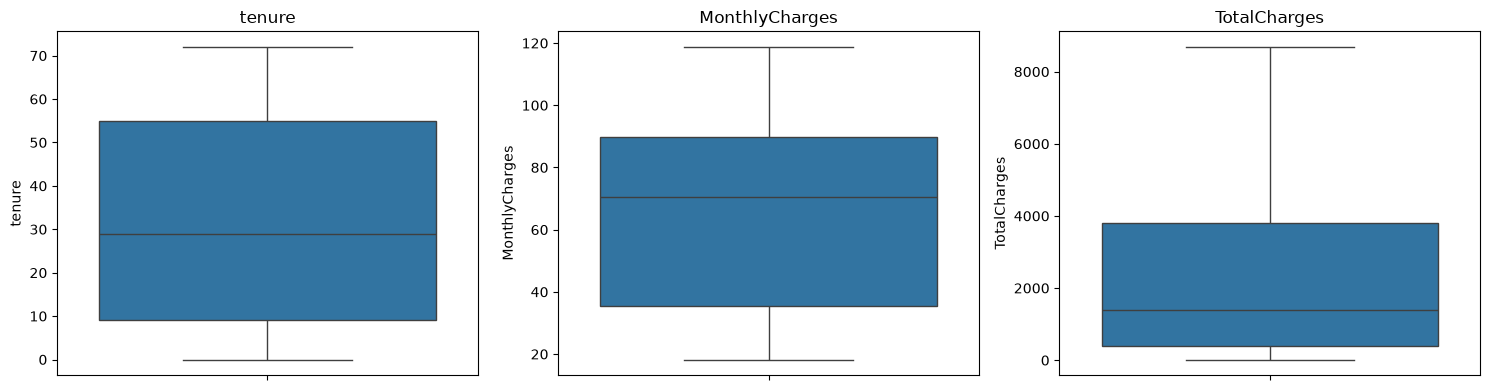

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numeric_df.columns):
    sns.boxplot(
        y=numeric_df[col],
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()



## 8. Target Variable Distribution

We examine the distribution of the target variable `Churn` to identify potential class imbalance.

**Findings:**
- No churn: 5,174 customers (73.5%).
- Churn: 1,869 customers (26.5%).

The dataset exhibits moderate class imbalance.

This will be considered during model evaluation, particularly when selecting metrics such as precision, recall, F1-score, and PR-AUC.


In [11]:

churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "count": churn_counts,
    "percentage": churn_pct.round(2)
})

display(target_summary)


,count,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54



## 9. Data Quality Audit — Final Summary
### 1. Dataset Overview
- Observations: 7,043
- Features and target: 21 columns
- Target variable: Churn

### 2. Missing Values
- 11 invalid values detected in TotalCharges.
- All correspond to customers with tenure = 0.
- No other missing values detected.

**Decision:** Convert TotalCharges to numeric and
impute 0 for these 11 customers, assuming no charges
have yet accumulated.

### 3. Duplicates and Identifiers
- Duplicate rows: 0
- Duplicate customer IDs: 0
- Missing customer IDs: 0
- Unique customers: 7,043

**Decision:** No duplicate removal required.

### 4. Categorical Data
- No unexpected categories identified.
- No inconsistencies in phone/internet service rules.
- SeniorCitizen is a binary categorical feature.

**Decision:** Encode categorical features during
preprocessing.

### 5. Numerical Data
- No negative values detected.
- Numerical ranges are plausible.
- TotalCharges requires type conversion.

### 6. Outlier Detection
Method: Interquartile Range (IQR), 1.5 × IQR

- tenure: 0 outliers
- MonthlyCharges: 0 outliers
- TotalCharges: 0 outliers

**Decision:** No outlier treatment required
based on the current audit.

### 7. Target Distribution
- No: 5,174 customers (73.5%)
- Yes: 1,869 customers (26.5%)

**Observation:** Moderate class imbalance.

### 8. Preprocessing Plan
- Preserve all 7,043 observations.
- Convert TotalCharges to numeric.
- Impute missing TotalCharges based on tenure = 0.
- Exclude customerID from predictive features.
- Encode categorical variables.
- Use a reproducible Scikit-learn pipeline.
- Fit learned preprocessing only on training data
  to avoid data leakage.
